# 강판 결함 유형 분류 분석 (Steel Plates Faults)

이미 발견된 강판 결함을 27개 측정 변수로 7가지 유형 중 하나로 분류하는 다중 클래스 분류 분석이다.

| 단계 | 내용 |
|---|---|
| 0 | 라이브러리 및 환경 설정 |
| 1 | 데이터 불러오기 및 CSV 저장 |
| 2 | 입력 변수·정답 열 구분 |
| 3 | [Q1] 정답 열 무결성 점검 |
| 4 | 기본 품질 점검 (결측·중복·논리 오류) |
| 5 | [Q2] 클래스 분포와 층화 분할 시 테스트셋 표본 수 |
| 6 | [Q3] 유형을 잘 구분하는 변수 |
| 7 | [Q4] 이상치: 측정 오류인가, 유형의 특징인가 |
| 8 | [Q5] 상관계수 0.9 이상 중복 변수 |
| 9 | 전처리 방침 확정 |
| 10 | 모델링: Baseline vs 불균형 처리 |
| 11 | 결과 비교: 개선 효과와 그 대가 |

## 0. 라이브러리 및 환경 설정

In [3]:
import os
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib import font_manager
from scipy import stats

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_predict
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import mutual_info_classif
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
                             confusion_matrix, precision_recall_fscore_support)

# SMOTE는 선택 사항 (pip install imbalanced-learn)
try:
    from imblearn.over_sampling import SMOTE
    from imblearn.pipeline import Pipeline as ImbPipeline
    HAS_IMBLEARN = True
except ImportError:
    HAS_IMBLEARN = False
    print("imbalanced-learn 미설치: SMOTE 비교는 건너뜁니다.")

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)

RANDOM_STATE = 42
TEST_SIZE = 0.2
CORR_THR = 0.9
OUT_DIR = "outputs_steel"
os.makedirs(OUT_DIR, exist_ok=True)

# 한글 폰트 (seaborn 스타일 지정 후 설정해야 유지됨)
sns.set_style("whitegrid")
_installed = {f.name for f in font_manager.fontManager.ttflist}
for _name in ["Malgun Gothic", "AppleGothic", "NanumGothic", "Noto Sans CJK KR"]:
    if _name in _installed:
        plt.rcParams["font.family"] = _name
        break
plt.rcParams["axes.unicode_minus"] = False

def savefig(name):
    plt.tight_layout()
    plt.savefig(os.path.join(OUT_DIR, name), dpi=150, bbox_inches="tight")
    plt.show()

## 1. 데이터 불러오기 및 CSV 저장

UCI 원본은 열 이름 파일(`Faults27x7_var`)과 데이터 파일(`Faults.NNA`, 헤더 없음, 탭/공백 구분)로 나뉘어 있다.
두 파일을 합쳐 CSV로 저장한 뒤, 이후 분석은 저장한 CSV를 기준으로 진행한다.

In [4]:
# 1-1. 열 이름 읽기 (Windows 줄바꿈 \r\n 대비 strip 처리)
with open("Faults27x7_var", "r") as f:
    cols = [line.strip() for line in f if line.strip()]

# 1-2. 데이터 읽기 (탭/공백 구분, 헤더 없음)
data = pd.read_csv("Faults.NNA", sep=r"\s+", header=None, names=cols)

# 1-3. 확인
print(data.shape)               # (1941, 34)
print(data.isna().sum().sum())  # 0

# 1-4. CSV로 저장
data.to_csv("steel_plates_faults.csv", index=False, encoding="utf-8-sig")

(1941, 34)
0


In [5]:
df = pd.read_csv("steel_plates_faults.csv")
display(df.head())
display(df.shape)
display(df.isna().sum().sum())
df.info()

,X_Minimum,X_Maximum,Y_Minimum,Y_Maximum,Pixels_Areas,X_Perimeter,Y_Perimeter,Sum_of_Luminosity,Minimum_of_Luminosity,Maximum_of_Luminosity,Length_of_Conveyer,TypeOfSteel_A300,TypeOfSteel_A400,Steel_Plate_Thickness,Edges_Index,Empty_Index,Square_Index,Outside_X_Index,Edges_X_Index,Edges_Y_Index,Outside_Global_Index,LogOfAreas,Log_X_Index,Log_Y_Index,Orientation_Index,Luminosity_Index,SigmoidOfAreas,Pastry,Z_Scratch,K_Scatch,Stains,Dirtiness,Bumps,Other_Faults
0,42,50,270900,270944,267,17,44,24220,76,108,1687,1,0,80,0.0498,0.2415,0.1818,0.0047,0.4706,1.0000,1.0,2.4265,0.9031,1.6435,0.8182,-0.2913,0.5822,1,0,0,0,0,0,0
1,645,651,2538079,2538108,108,10,30,11397,84,123,1687,1,0,80,0.7647,0.3793,0.2069,0.0036,0.6000,0.9667,1.0,2.0334,0.7782,1.4624,0.7931,-0.1756,0.2984,1,0,0,0,0,0,0
2,829,835,1553913,1553931,71,8,19,7972,99,125,1623,1,0,100,0.9710,0.3426,0.3333,0.0037,0.7500,0.9474,1.0,1.8513,0.7782,1.2553,0.6667,-0.1228,0.2150,1,0,0,0,0,0,0
3,853,860,369370,369415,176,13,45,18996,99,126,1353,0,1,290,0.7287,0.4413,0.1556,0.0052,0.5385,1.0000,1.0,2.2455,0.8451,1.6532,0.8444,-0.1568,0.5212,1,0,0,0,0,0,0
4,1289,1306,498078,498335,2409,60,260,246930,37,126,1353,0,1,185,0.0695,0.4486,0.0662,0.0126,0.2833,0.9885,1.0,3.3818,1.2305,2.4099,0.9338,-0.1992,1.0000,1,0,0,0,0,0,0


(1941, 34)

np.int64(0)

<class 'pandas.DataFrame'>
RangeIndex: 1941 entries, 0 to 1940
Data columns (total 34 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   X_Minimum              1941 non-null   int64  
 1   X_Maximum              1941 non-null   int64  
 2   Y_Minimum              1941 non-null   int64  
 3   Y_Maximum              1941 non-null   int64  
 4   Pixels_Areas           1941 non-null   int64  
 5   X_Perimeter            1941 non-null   int64  
 6   Y_Perimeter            1941 non-null   int64  
 7   Sum_of_Luminosity      1941 non-null   int64  
 8   Minimum_of_Luminosity  1941 non-null   int64  
 9   Maximum_of_Luminosity  1941 non-null   int64  
 10  Length_of_Conveyer     1941 non-null   int64  
 11  TypeOfSteel_A300       1941 non-null   int64  
 12  TypeOfSteel_A400       1941 non-null   int64  
 13  Steel_Plate_Thickness  1941 non-null   int64  
 14  Edges_Index            1941 non-null   float64
 15  Empty_Index    

## 2. 입력 변수와 정답 열 구분

열 이름 파일의 순서대로 앞 27개는 측정 변수, 뒤 7개는 결함 유형 표시(one-hot) 열이다.
변수는 해석 편의를 위해 위치·크기·밝기·형상·제품 5개 그룹으로 묶는다.

In [6]:
FEATURES = cols[:27]
TARGETS = cols[27:]
MINORITY = ["Stains", "Dirtiness"]

assert len(FEATURES) == 27 and len(TARGETS) == 7, "열 개수가 예상과 다릅니다."
print("입력 변수 27개:", FEATURES)
print("정답 열 7개   :", TARGETS)

FEATURE_GROUPS = {
    "위치": ["X_Minimum", "X_Maximum", "Y_Minimum", "Y_Maximum", "Length_of_Conveyer"],
    "크기": ["Pixels_Areas", "X_Perimeter", "Y_Perimeter", "LogOfAreas",
             "Log_X_Index", "Log_Y_Index", "SigmoidOfAreas"],
    "밝기": ["Sum_of_Luminosity", "Minimum_of_Luminosity", "Maximum_of_Luminosity",
             "Luminosity_Index"],
    "형상": ["Edges_Index", "Empty_Index", "Square_Index", "Outside_X_Index",
             "Edges_X_Index", "Edges_Y_Index", "Outside_Global_Index", "Orientation_Index"],
    "제품": ["TypeOfSteel_A300", "TypeOfSteel_A400", "Steel_Plate_Thickness"],
}
GROUP_OF = {f: g for g, fs in FEATURE_GROUPS.items() for f in fs}

# 열 이름 파일과 그룹 정의가 일치하는지 확인
ungrouped = [f for f in FEATURES if f not in GROUP_OF]
print("그룹 미지정 변수:", ungrouped if ungrouped else "없음")
for f in ungrouped:
    GROUP_OF[f] = "기타"

입력 변수 27개: ['X_Minimum', 'X_Maximum', 'Y_Minimum', 'Y_Maximum', 'Pixels_Areas', 'X_Perimeter', 'Y_Perimeter', 'Sum_of_Luminosity', 'Minimum_of_Luminosity', 'Maximum_of_Luminosity', 'Length_of_Conveyer', 'TypeOfSteel_A300', 'TypeOfSteel_A400', 'Steel_Plate_Thickness', 'Edges_Index', 'Empty_Index', 'Square_Index', 'Outside_X_Index', 'Edges_X_Index', 'Edges_Y_Index', 'Outside_Global_Index', 'LogOfAreas', 'Log_X_Index', 'Log_Y_Index', 'Orientation_Index', 'Luminosity_Index', 'SigmoidOfAreas']
정답 열 7개   : ['Pastry', 'Z_Scratch', 'K_Scatch', 'Stains', 'Dirtiness', 'Bumps', 'Other_Faults']
그룹 미지정 변수: 없음


## 3. [Q1] 정답 표시 7개 열은 0/1이며 행마다 합이 정확히 1인가?

하나의 결함에 유형이 두 개 이상 표시되거나 아무것도 표시되지 않은 행은 정답을 믿을 수 없으므로 제외한다.
점검 후 one-hot 7개 열을 `Fault`라는 하나의 범주형 열로 바꾼다.

In [7]:
label_values = np.unique(df[TARGETS].values)
row_sum = df[TARGETS].sum(axis=1)

print("정답 열에 등장하는 값:", label_values.tolist())
print("0/1만 존재하는가     :", set(label_values).issubset({0, 1}))
print("\n행별 합계 분포:")
display(row_sum.value_counts().sort_index().rename("행 수").to_frame())

bad_label = df[row_sum != 1]
print(f"합계가 1이 아닌 행: {len(bad_label)}건")
if len(bad_label):
    display(bad_label.head())

df = df[row_sum == 1].copy()
df["Fault"] = df[TARGETS].idxmax(axis=1)
display(df[TARGETS + ["Fault"]].head())

정답 열에 등장하는 값: [0, 1]
0/1만 존재하는가     : True

행별 합계 분포:


,행 수
1,1941


합계가 1이 아닌 행: 0건


,Pastry,Z_Scratch,K_Scatch,Stains,Dirtiness,Bumps,Other_Faults,Fault
0,1,0,0,0,0,0,0,Pastry
1,1,0,0,0,0,0,0,Pastry
2,1,0,0,0,0,0,0,Pastry
3,1,0,0,0,0,0,0,Pastry
4,1,0,0,0,0,0,0,Pastry


## 4. 기본 품질 점검

결측값, 중복 행, 측정값은 같은데 정답이 다른 충돌 행, 강종 두 열의 일관성, 좌표의 최소·최대 논리를 확인한다.

In [8]:
print("결측값 총합:", int(df[FEATURES].isna().sum().sum()))

dup_full = df.duplicated(subset=FEATURES + ["Fault"]).sum()
dup_x_mask = df.duplicated(subset=FEATURES, keep=False)
conflict = df[dup_x_mask].groupby(FEATURES)["Fault"].nunique() if dup_x_mask.any() else pd.Series(dtype=int)
print("완전 중복 행(변수+정답 동일)        :", dup_full)
print("변수는 같은데 정답이 다른 충돌 그룹 :", int((conflict > 1).sum()))

non_numeric = [c for c in FEATURES if not pd.api.types.is_numeric_dtype(df[c])]
print("숫자형이 아닌 변수                  :", non_numeric if non_numeric else "없음")

steel_sum = df["TypeOfSteel_A300"] + df["TypeOfSteel_A400"]
print("강종 A300 + A400 ≠ 1 인 행          :", int((steel_sum != 1).sum()))
print("X_Minimum > X_Maximum 인 행         :", int((df["X_Minimum"] > df["X_Maximum"]).sum()))
print("Y_Minimum > Y_Maximum 인 행         :", int((df["Y_Minimum"] > df["Y_Maximum"]).sum()))

df = df.drop_duplicates(subset=FEATURES + ["Fault"]).reset_index(drop=True)
print("\n중복 제거 후 데이터 크기:", df.shape)

결측값 총합: 0
완전 중복 행(변수+정답 동일)        : 0
변수는 같은데 정답이 다른 충돌 그룹 : 0
숫자형이 아닌 변수                  : 없음
강종 A300 + A400 ≠ 1 인 행          : 0
X_Minimum > X_Maximum 인 행         : 0
Y_Minimum > Y_Maximum 인 행         : 0

중복 제거 후 데이터 크기: (1941, 35)


In [9]:
desc = df[FEATURES].describe().T
desc["skew"] = df[FEATURES].skew()
desc["nunique"] = df[FEATURES].nunique()
desc.round(3).to_csv(os.path.join(OUT_DIR, "eda_describe.csv"), encoding="utf-8-sig")
display(desc.round(3))

,count,mean,std,min,25%,50%,75%,max,skew,nunique
X_Minimum,1941.0,571.136,520.691,0.000,51.000,435.000,1053.000,1.705000e+03,0.501,962
X_Maximum,1941.0,617.964,497.627,4.000,192.000,467.000,1072.000,1.713000e+03,0.524,994
Y_Minimum,1941.0,1650684.868,1774578.415,6712.000,471253.000,1204128.000,2183073.000,1.298766e+07,2.811,1939
Y_Maximum,1941.0,1650738.705,1774590.089,6724.000,471281.000,1204136.000,2183084.000,1.298769e+07,2.811,1940
Pixels_Areas,1941.0,1893.878,5168.460,2.000,84.000,174.000,822.000,1.526550e+05,14.084,920
X_Perimeter,1941.0,111.855,301.209,2.000,15.000,26.000,84.000,1.044900e+04,21.539,399
Y_Perimeter,1941.0,82.966,426.483,1.000,13.000,25.000,83.000,1.815200e+04,39.293,317
Sum_of_Luminosity,1941.0,206312.148,512293.588,250.000,9522.000,19202.000,83011.000,1.159141e+07,7.731,1909
Minimum_of_Luminosity,1941.0,84.549,32.134,0.000,63.000,90.000,106.000,2.030000e+02,-0.107,161
Maximum_of_Luminosity,1941.0,130.194,18.691,37.000,124.000,127.000,140.000,2.530000e+02,1.287,100


## 5. [Q2] 7개 유형의 불균형 정도와 층화 분할 시 테스트셋 소수 유형 표본 수

테스트셋에 소수 유형이 몇 건 남는지에 따라, 1건을 맞히고 틀리는 것이 Recall을 몇 %p 바꾸는지가 결정된다.

,표본 수,비율(%)
Fault,,
Other_Faults,673,34.67
Bumps,402,20.71
K_Scatch,391,20.14
Z_Scratch,190,9.79
Pastry,158,8.14
Stains,72,3.71
Dirtiness,55,2.83


불균형 비율(최다/최소): Other_Faults / Dirtiness = 12.24배


,전체,테스트셋,1건당 Recall 변동(%p)
Fault,,,
Other_Faults,673,135,0.7
Bumps,402,81,1.2
K_Scatch,391,78,1.3
Z_Scratch,190,38,2.6
Pastry,158,32,3.1
Stains,72,14,7.1
Dirtiness,55,11,9.1


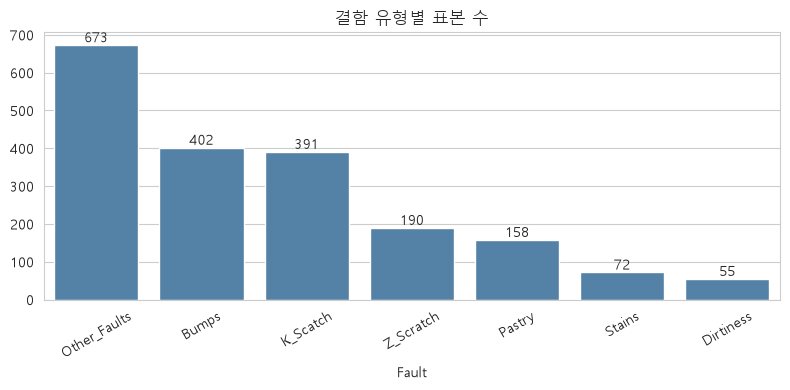

In [10]:
counts = df["Fault"].value_counts()
dist = pd.DataFrame({"표본 수": counts, "비율(%)": (counts / counts.sum() * 100).round(2)})
display(dist)
print(f"불균형 비율(최다/최소): {counts.idxmax()} / {counts.idxmin()} = {counts.max() / counts.min():.2f}배")

_, _test_tmp = train_test_split(df, test_size=TEST_SIZE, stratify=df["Fault"], random_state=RANDOM_STATE)
test_counts = _test_tmp["Fault"].value_counts().reindex(counts.index)
split_table = pd.DataFrame({"전체": counts, "테스트셋": test_counts,
                            "1건당 Recall 변동(%p)": (100 / test_counts).round(1)})
display(split_table)
dist.to_csv(os.path.join(OUT_DIR, "q2_class_distribution.csv"), encoding="utf-8-sig")

plt.figure(figsize=(8, 4))
ax = sns.barplot(x=counts.index, y=counts.values, color="steelblue")
for i, v in enumerate(counts.values):
    ax.text(i, v, str(v), ha="center", va="bottom")
plt.title("결함 유형별 표본 수")
plt.xticks(rotation=30)
savefig("q2_class_distribution.png")

## 6. [Q3] 결함의 크기·밝기·형상·강종·두께 중 어떤 변수가 유형을 가장 잘 구분하는가?

- **Kruskal-Wallis 효과크기(ε²)**: 7개 유형 간 분포 차이의 크기. 정규분포를 가정하지 않으므로 꼬리가 긴 변수에도 쓸 수 있다.
- **상호정보량**: 변수 값을 알 때 유형에 대한 불확실성이 얼마나 줄어드는지. 비선형 관계도 반영한다.

In [11]:
labels_order = counts.index.tolist()
n, k = len(df), df["Fault"].nunique()
rows = []
for f in FEATURES:
    samples = [df.loc[df["Fault"] == g, f].values for g in labels_order]
    if df[f].nunique() <= 1:
        h, p = 0.0, 1.0
    else:
        h, p = stats.kruskal(*samples)
    rows.append({"변수": f, "그룹": GROUP_OF[f], "H": h, "p": p,
                 "효과크기(ε²)": max((h - k + 1) / (n - k), 0)})
disc = pd.DataFrame(rows)
disc["상호정보량"] = mutual_info_classif(df[FEATURES], df["Fault"], random_state=RANDOM_STATE)
disc = disc.sort_values("효과크기(ε²)", ascending=False).reset_index(drop=True)
disc.to_csv(os.path.join(OUT_DIR, "q3_feature_discrimination.csv"), index=False, encoding="utf-8-sig")
display(disc.round(4))

print("그룹별 평균 구분력")
display(disc.groupby("그룹")[["효과크기(ε²)", "상호정보량"]].mean()
        .sort_values("효과크기(ε²)", ascending=False).round(4))

,변수,그룹,H,p,효과크기(ε²),상호정보량
0,Sum_of_Luminosity,밝기,827.9525,0.0,0.4250,0.4482
1,Outside_X_Index,형상,821.6631,0.0,0.4217,0.5338
2,Log_X_Index,크기,809.4836,0.0,0.4155,0.4061
3,LogOfAreas,크기,786.3354,0.0,0.4035,0.4373
4,Pixels_Areas,크기,786.3354,0.0,0.4035,0.4318
5,Y_Perimeter,크기,736.9414,0.0,0.3779,0.3867
6,X_Perimeter,크기,734.4772,0.0,0.3767,0.4085
7,Edges_Y_Index,형상,715.2621,0.0,0.3667,0.3306
8,SigmoidOfAreas,크기,705.2138,0.0,0.3615,0.3763
9,Log_Y_Index,크기,667.8000,0.0,0.3422,0.3700


그룹별 평균 구분력


,효과크기(ε²),상호정보량
그룹,,
크기,0.3830,0.4024
제품,0.3390,0.3368
형상,0.2347,0.2998
밝기,0.2164,0.3007
위치,0.1645,0.3540


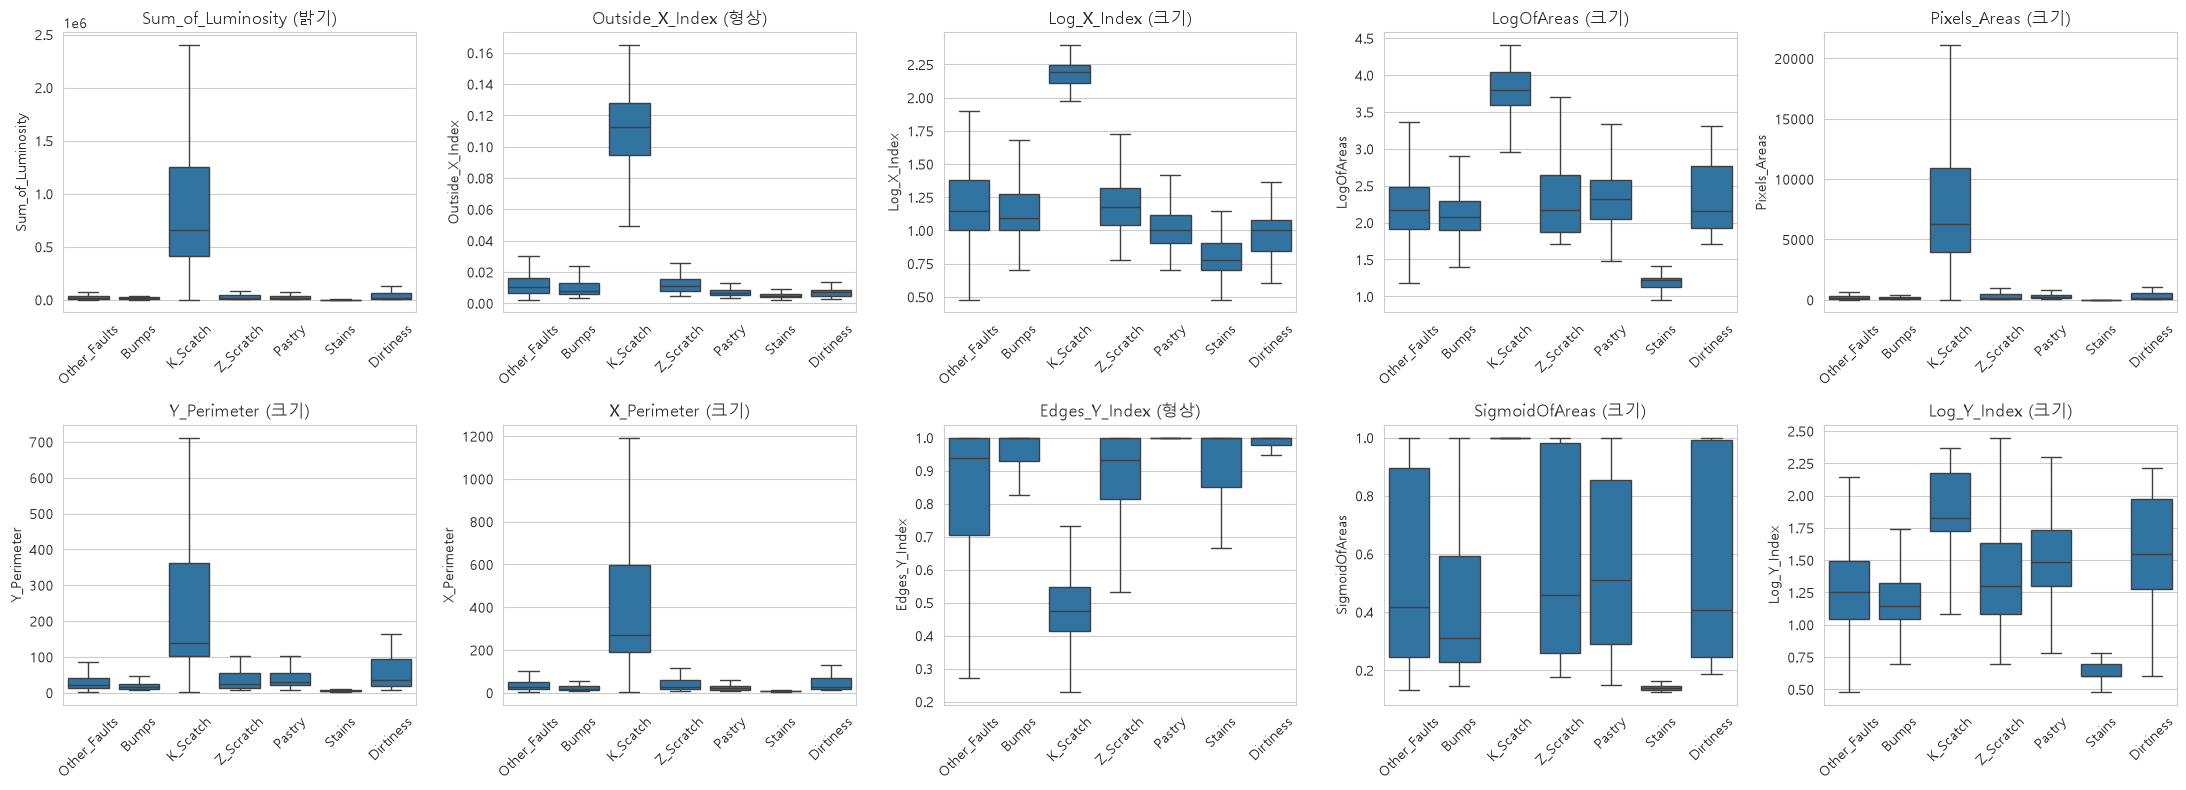

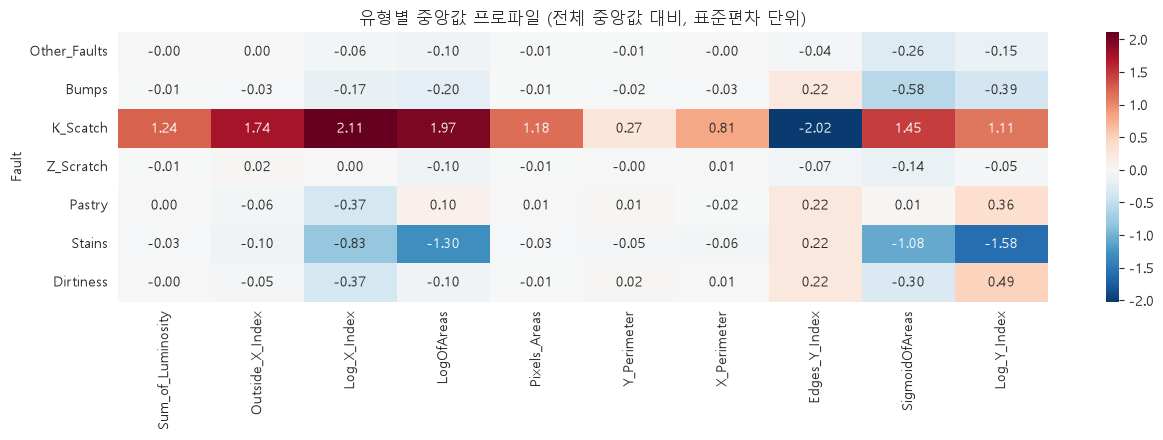

In [12]:
TOP_N = 10
top_feats = disc["변수"].head(TOP_N).tolist()

fig, axes = plt.subplots(2, 5, figsize=(22, 8))
for ax, f in zip(axes.ravel(), top_feats):
    sns.boxplot(data=df, x="Fault", y=f, order=labels_order, ax=ax, showfliers=False)
    ax.set_title(f"{f} ({GROUP_OF[f]})")
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=45)
savefig("q3_top_features_boxplot.png")

# 유형별 중앙값 프로파일: 각 유형이 전체 대비 어느 쪽으로 치우치는가
med = df.groupby("Fault")[top_feats].median().reindex(labels_order)
med_z = (med - df[top_feats].median()) / (df[top_feats].std() + 1e-9)
plt.figure(figsize=(13, 4.5))
sns.heatmap(med_z, cmap="RdBu_r", center=0, annot=True, fmt=".2f")
plt.title("유형별 중앙값 프로파일 (전체 중앙값 대비, 표준편차 단위)")
savefig("q3_class_profile_heatmap.png")

유형별 강종 비율


TypeOfSteel_A300,A300,A400
Fault,,
Other_Faults,0.395,0.605
Bumps,0.694,0.306
K_Scatch,0.003,0.997
Z_Scratch,0.905,0.095
Pastry,0.310,0.690
Stains,0.014,0.986
Dirtiness,0.164,0.836


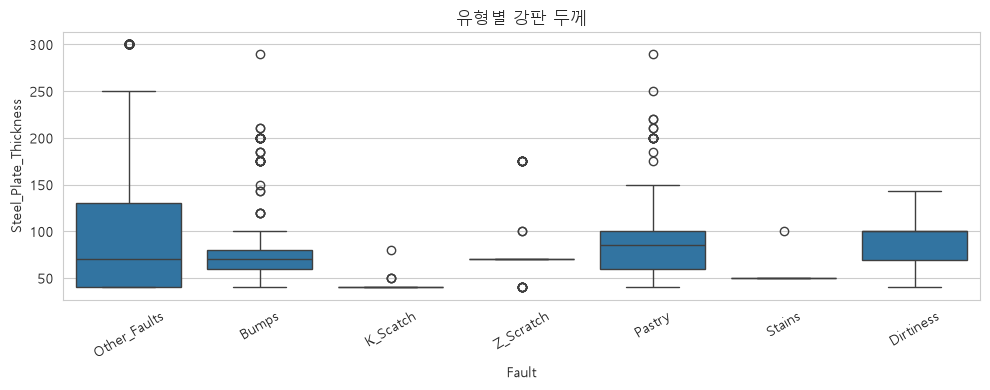

In [13]:
# 제품 특성(강종·두께)과 유형의 관계
steel = df["TypeOfSteel_A300"].map({1: "A300", 0: "A400"})
print("유형별 강종 비율")
display(pd.crosstab(df["Fault"], steel, normalize="index").reindex(labels_order).round(3))

plt.figure(figsize=(10, 4))
sns.boxplot(data=df, x="Fault", y="Steel_Plate_Thickness", order=labels_order)
plt.title("유형별 강판 두께")
plt.xticks(rotation=30)
savefig("q3_thickness_by_fault.png")

## 7. [Q4] 이상치로 보이는 값은 측정 오류인가, 특정 유형의 정상적인 특징인가?

IQR(1.5배) 기준으로 이상치를 찾은 뒤, 이상치가 특정 유형에 몰려 있는지 **집중도(lift)** 로 판단한다.

- lift = (이상치 안에서 해당 유형 비율) / (전체에서 해당 유형 비율)
- lift ≥ 2 → 그 유형의 특징일 가능성이 높으므로 제거하지 않는다.
- 음수 면적처럼 물리적으로 불가능한 값 → 측정·입력 오류 후보로 개별 확인한다.

In [14]:
base_ratio = df["Fault"].value_counts(normalize=True)
SIGNED_OK = {"Orientation_Index", "Luminosity_Index"}  # 정의상 음수가 가능한 지표
rows = []
for f in FEATURES:
    if df[f].nunique() <= 2:  # 이진 변수 제외
        continue
    q1, q3 = df[f].quantile([0.25, 0.75])
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    mask = (df[f] < lo) | (df[f] > hi)
    row = {"변수": f, "그룹": GROUP_OF[f], "이상치 수": int(mask.sum()),
           "이상치 비율(%)": round(mask.mean() * 100, 2),
           "음수값 수": 0 if f in SIGNED_OK else int((df[f] < 0).sum())}
    if mask.any():
        share = df.loc[mask, "Fault"].value_counts(normalize=True)
        top = share.idxmax()
        row.update({"최다 유형": top, "최다 유형 점유율(%)": round(share.max() * 100, 1),
                    "집중도(lift)": round(share[top] / base_ratio[top], 2)})
    rows.append(row)

outliers = pd.DataFrame(rows).sort_values("이상치 수", ascending=False).reset_index(drop=True)
outliers["판단"] = np.select(
    [outliers["음수값 수"] > 0, outliers["집중도(lift)"].fillna(0) >= 2, outliers["이상치 수"] == 0],
    ["오류 후보(개별 확인)", "유형 특징(유지)", "이상치 없음"], default="일반 꼬리값(변환 검토)")
outliers.to_csv(os.path.join(OUT_DIR, "q4_outliers.csv"), index=False, encoding="utf-8-sig")
display(outliers)

,변수,그룹,이상치 수,이상치 비율(%),음수값 수,최다 유형,최다 유형 점유율(%),집중도(lift),판단
0,Sum_of_Luminosity,밝기,399,20.56,0,K_Scatch,82.5,4.09,유형 특징(유지)
1,Pixels_Areas,크기,395,20.35,0,K_Scatch,82.5,4.10,유형 특징(유지)
2,Outside_X_Index,형상,370,19.06,0,K_Scatch,87.8,4.36,유형 특징(유지)
3,X_Perimeter,크기,352,18.13,0,K_Scatch,83.5,4.15,유형 특징(유지)
4,Steel_Plate_Thickness,제품,240,12.36,0,Other_Faults,69.6,2.01,유형 특징(유지)
5,Y_Perimeter,크기,179,9.22,0,K_Scatch,70.4,3.49,유형 특징(유지)
6,Maximum_of_Luminosity,밝기,146,7.52,0,Other_Faults,52.1,1.50,일반 꼬리값(변환 검토)
7,Luminosity_Index,밝기,134,6.90,0,Other_Faults,46.3,1.33,일반 꼬리값(변환 검토)
8,Y_Minimum,위치,81,4.17,0,Other_Faults,32.1,0.93,일반 꼬리값(변환 검토)
9,Y_Maximum,위치,81,4.17,0,Other_Faults,32.1,0.93,일반 꼬리값(변환 검토)


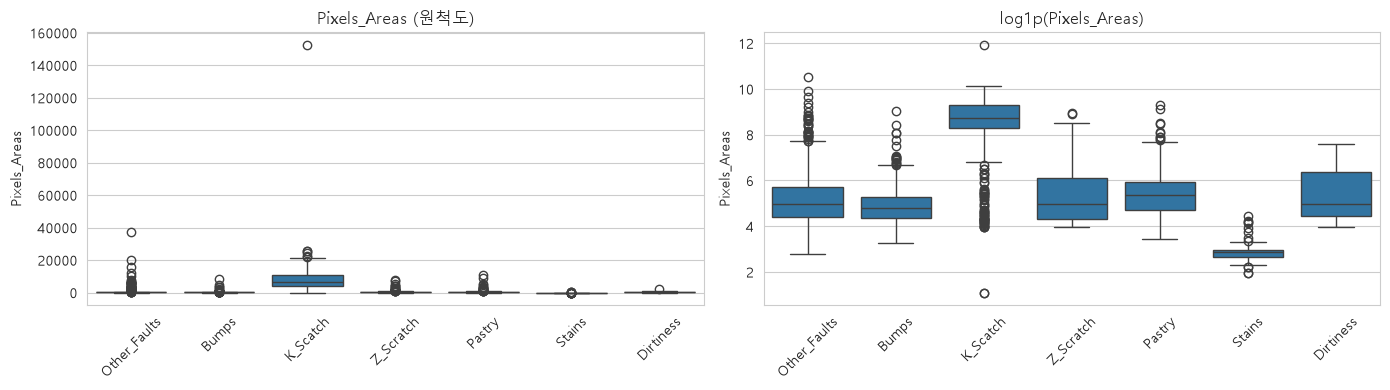

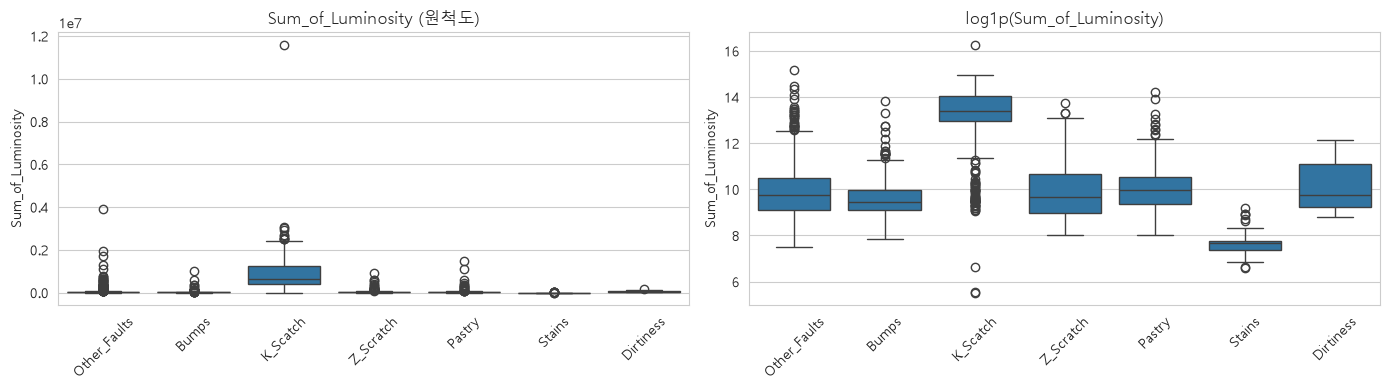

In [15]:
# 꼬리가 긴 대표 변수: 원척도 vs 로그척도
for f in ["Pixels_Areas", "Sum_of_Luminosity"]:
    fig, axes = plt.subplots(1, 2, figsize=(14, 4))
    sns.boxplot(data=df, x="Fault", y=f, order=labels_order, ax=axes[0])
    axes[0].set_title(f"{f} (원척도)")
    sns.boxplot(x=df["Fault"], y=np.log1p(df[f].clip(lower=0)), order=labels_order, ax=axes[1])
    axes[1].set_title(f"log1p({f})")
    for ax in axes:
        ax.tick_params(axis="x", rotation=45)
        ax.set_xlabel("")
    savefig(f"q4_outlier_{f}.png")

## 8. [Q5] 서로 중복되는(상관계수 0.9 이상) 변수는 무엇인가?

Pearson(선형 관계)과 Spearman(순위 관계) 중 하나라도 |r| ≥ 0.9이면 중복 후보로 본다.

|r| >= 0.9 인 쌍: 21개


,변수1,변수2,Pearson,Spearman
0,Y_Minimum,Y_Maximum,1.000,1.000
1,TypeOfSteel_A300,TypeOfSteel_A400,-1.000,-1.000
2,X_Minimum,X_Maximum,0.988,0.949
3,Pixels_Areas,Sum_of_Luminosity,0.979,0.985
4,Pixels_Areas,X_Perimeter,0.967,0.896
5,X_Perimeter,Sum_of_Luminosity,0.913,0.895
6,X_Perimeter,Y_Perimeter,0.912,0.881
7,LogOfAreas,Log_Y_Index,0.883,0.909
8,LogOfAreas,SigmoidOfAreas,0.878,0.977
9,Pixels_Areas,Y_Perimeter,0.827,0.949


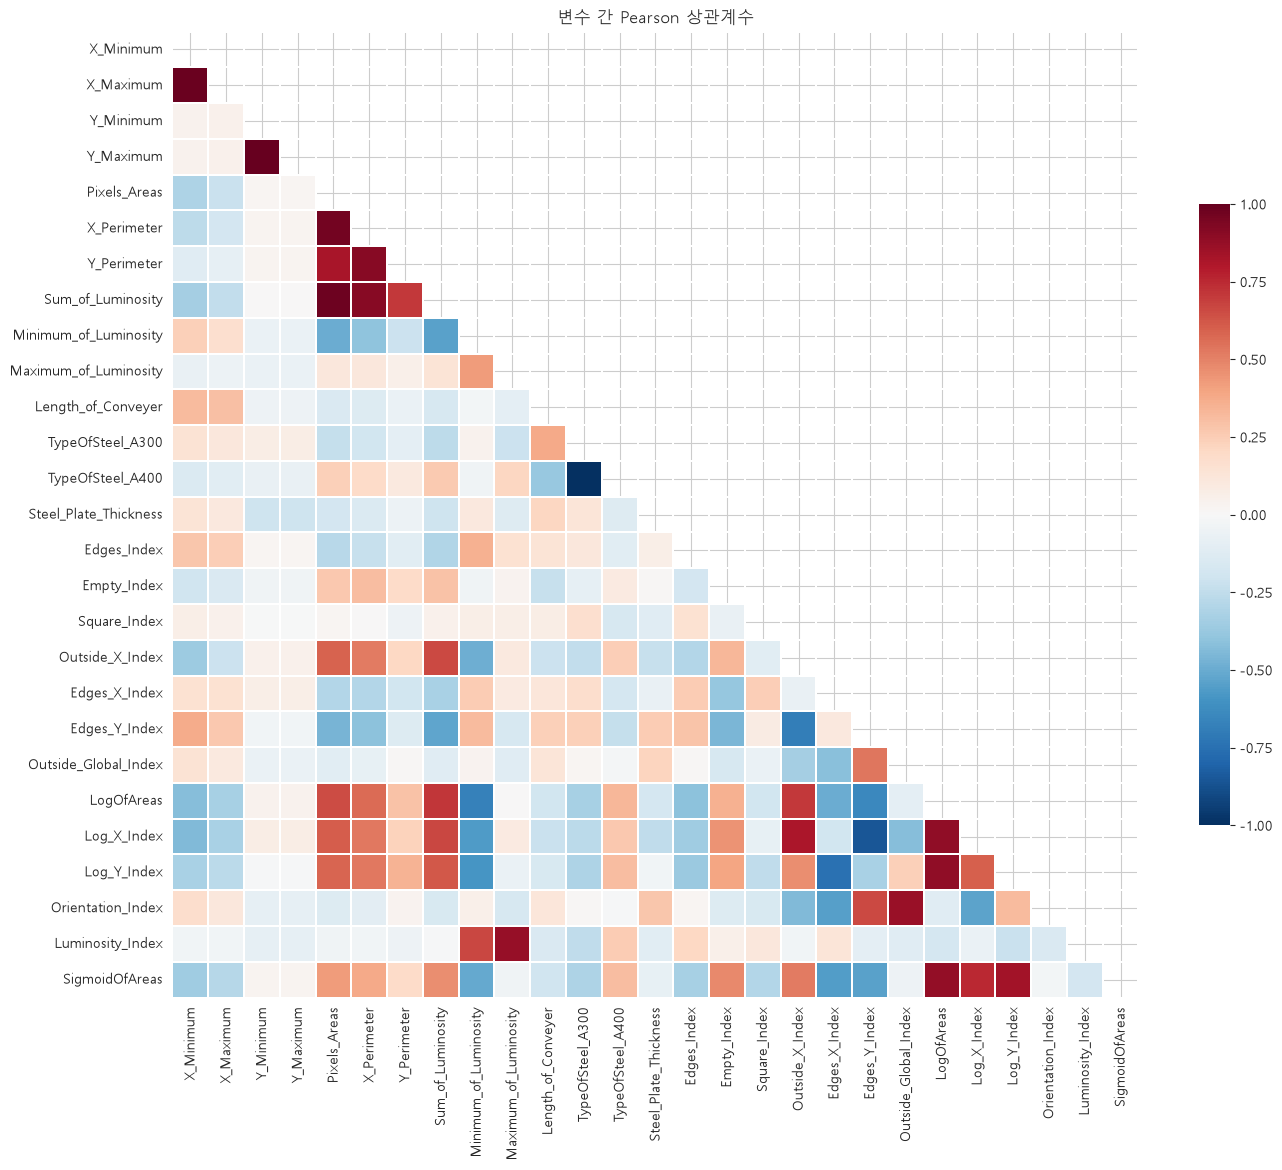

In [16]:
corr_p = df[FEATURES].corr(method="pearson")
corr_s = df[FEATURES].corr(method="spearman")

pairs = []
for i, a in enumerate(FEATURES):
    for b in FEATURES[i + 1:]:
        if abs(corr_p.loc[a, b]) >= CORR_THR or abs(corr_s.loc[a, b]) >= CORR_THR:
            pairs.append({"변수1": a, "변수2": b,
                          "Pearson": round(corr_p.loc[a, b], 3),
                          "Spearman": round(corr_s.loc[a, b], 3)})
pairs = pd.DataFrame(pairs, columns=["변수1", "변수2", "Pearson", "Spearman"])
if len(pairs):
    pairs = pairs.reindex(pairs["Pearson"].abs().sort_values(ascending=False).index).reset_index(drop=True)
pairs.to_csv(os.path.join(OUT_DIR, "q5_high_corr_pairs.csv"), index=False, encoding="utf-8-sig")
print(f"|r| >= {CORR_THR} 인 쌍: {len(pairs)}개")
display(pairs)

plt.figure(figsize=(14, 12))
sns.heatmap(corr_p, mask=np.triu(np.ones_like(corr_p, dtype=bool)), cmap="RdBu_r",
            center=0, vmin=-1, vmax=1, square=True, linewidths=0.3, cbar_kws={"shrink": 0.6})
plt.title("변수 간 Pearson 상관계수")
savefig("q5_correlation_heatmap.png")

## 9. 전처리 방침 확정

| 항목 | 방침 |
|---|---|
| 정답 | 행 합계가 1인 행만 사용, one-hot → `Fault` 단일 열 |
| 중복 | 완전 중복 행 제거 |
| 이상치 | 제거하지 않음. 꼬리가 긴 크기·밝기 변수는 log1p 변환 |
| 중복 변수 | 상관 쌍마다 구분력(ε²)이 낮은 쪽을 선형 모델에서 제외, 트리 모델은 전체 사용 |
| 분할 | 층화 분할(8:2) + 학습셋 내부 층화 5-fold 교차검증 |
| 불균형 | class_weight 보정, (설치 시) SMOTE 비교 |

In [17]:
LOG_COLS = ["Pixels_Areas", "X_Perimeter", "Y_Perimeter", "Sum_of_Luminosity"]

# 구분력이 낮은 쪽을 제거 후보로 선택
score = disc.set_index("변수")["효과크기(ε²)"]
drop_cols = {"TypeOfSteel_A400"}  # A300과 합이 항상 1 → 같은 정보
for _, r in pairs.iterrows():
    a, b = r["변수1"], r["변수2"]
    if a in drop_cols or b in drop_cols:
        continue
    drop_cols.add(a if score[a] < score[b] else b)
drop_cols = sorted(drop_cols)

LIN_FEATURES = [f for f in FEATURES if f not in drop_cols]
print("선형 모델에서 제외할 변수:", drop_cols)
print(f"선형 모델 사용 변수 {len(LIN_FEATURES)}개 / 트리 모델 사용 변수 {len(FEATURES)}개")

def preprocess(X):
    X = X.copy()
    for c in LOG_COLS:
        X[c] = np.log1p(X[c].clip(lower=0))
    return X

X = preprocess(df[FEATURES])
y = df["Fault"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, stratify=y, random_state=RANDOM_STATE)
print(f"학습 {len(X_train)}건 / 테스트 {len(X_test)}건")
display(pd.DataFrame({"학습": y_train.value_counts(), "테스트": y_test.value_counts()}).reindex(labels_order))

선형 모델에서 제외할 변수: ['LogOfAreas', 'Log_X_Index', 'Log_Y_Index', 'Pixels_Areas', 'SigmoidOfAreas', 'TypeOfSteel_A400', 'X_Maximum', 'X_Perimeter', 'Y_Minimum', 'Y_Perimeter']
선형 모델 사용 변수 17개 / 트리 모델 사용 변수 27개
학습 1552건 / 테스트 389건


,학습,테스트
Fault,,
Other_Faults,538,135
Bumps,321,81
K_Scatch,313,78
Z_Scratch,152,38
Pastry,126,32
Stains,58,14
Dirtiness,44,11


## 10. 모델링: Baseline vs 불균형 처리 (주지표 Macro F1)

- **Baseline**: 불균형 처리 없이 학습
- **ClassWeight**: 소수 유형을 틀렸을 때 손해를 더 크게 주어 학습
- **SMOTE**: 소수 유형 표본을 인공적으로 늘려 학습 (학습 fold 안에서만 적용)

테스트셋은 최종 확인용으로만 쓰고, 모델 비교에는 학습셋 내부 5-fold CV Macro F1을 함께 본다.

In [18]:
def make_lr(cw=None):
    return LogisticRegression(max_iter=3000, class_weight=cw)

def make_rf(cw=None):
    return RandomForestClassifier(n_estimators=500, class_weight=cw, n_jobs=-1,
                                  random_state=RANDOM_STATE)

models = [
    ("LR_Baseline",    Pipeline([("sc", StandardScaler()), ("m", make_lr())]),            LIN_FEATURES),
    ("LR_ClassWeight", Pipeline([("sc", StandardScaler()), ("m", make_lr("balanced"))]),  LIN_FEATURES),
    ("RF_Baseline",    Pipeline([("m", make_rf())]),                                      FEATURES),
    ("RF_ClassWeight", Pipeline([("m", make_rf("balanced_subsample"))]),                  FEATURES),
]
if HAS_IMBLEARN:
    models += [
        ("LR_SMOTE", ImbPipeline([("sc", StandardScaler()), ("sm", SMOTE(random_state=RANDOM_STATE)),
                                  ("m", make_lr())]), LIN_FEATURES),
        ("RF_SMOTE", ImbPipeline([("sc", StandardScaler()), ("sm", SMOTE(random_state=RANDOM_STATE)),
                                  ("m", make_rf())]), FEATURES),
    ]

def per_class_table(y_true, y_pred, labels):
    p, r, f1, s = precision_recall_fscore_support(y_true, y_pred, labels=labels, zero_division=0)
    cm = confusion_matrix(y_true, y_pred, labels=labels)
    fp = cm.sum(axis=0) - np.diag(cm)  # 다른 유형을 이 유형으로 잘못 판정 = 오경보
    return pd.DataFrame({"Precision": p, "Recall": r, "F1": f1, "Support": s, "오경보(FP)": fp},
                        index=labels)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
summary_rows, per_class, fitted = [], {}, {}

for name, pipe, feats in models:
    cv_pred = cross_val_predict(pipe, X_train[feats], y_train, cv=cv, n_jobs=-1)
    pipe.fit(X_train[feats], y_train)
    y_pred = pipe.predict(X_test[feats])
    fitted[name] = (pipe, feats, y_pred)

    pc = per_class_table(y_test, y_pred, labels_order)
    per_class[name] = pc
    row = {"모델": name,
           "CV Macro F1": f1_score(y_train, cv_pred, average="macro"),
           "Test Macro F1": f1_score(y_test, y_pred, average="macro"),
           "Test Accuracy": accuracy_score(y_test, y_pred),
           "Test Weighted F1": f1_score(y_test, y_pred, average="weighted")}
    for m in MINORITY:
        row[f"{m} Recall"] = pc.loc[m, "Recall"]
        row[f"{m} F1"] = pc.loc[m, "F1"]
        row[f"{m} 오경보"] = int(pc.loc[m, "오경보(FP)"])
    summary_rows.append(row)

    print(f"\n========== {name} ==========")
    print(classification_report(y_test, y_pred, labels=labels_order, digits=3, zero_division=0))

summary = pd.DataFrame(summary_rows).set_index("모델")
summary.round(4).to_csv(os.path.join(OUT_DIR, "model_summary.csv"), encoding="utf-8-sig")
pd.concat(per_class, names=["모델", "유형"]).round(4).to_csv(
    os.path.join(OUT_DIR, "model_per_class.csv"), encoding="utf-8-sig")
display(summary.round(3))


========== LR_Baseline ==========
              precision    recall  f1-score   support

Other_Faults      0.618     0.719     0.664       135
       Bumps      0.667     0.519     0.583        81
    K_Scatch      0.934     0.910     0.922        78
   Z_Scratch      0.868     0.868     0.868        38
      Pastry      0.500     0.500     0.500        32
      Stains      0.857     0.857     0.857        14
   Dirtiness      0.778     0.636     0.700        11

    accuracy                          0.715       389
   macro avg      0.746     0.716     0.728       389
weighted avg      0.719     0.715     0.714       389


========== LR_ClassWeight ==========
              precision    recall  f1-score   support

Other_Faults      0.750     0.400     0.522       135
       Bumps      0.628     0.605     0.616        81
    K_Scatch      0.899     0.910     0.904        78
   Z_Scratch      0.630     0.895     0.739        38
      Pastry      0.407     0.750     0.527        32
     

,CV Macro F1,Test Macro F1,Test Accuracy,Test Weighted F1,Stains Recall,Stains F1,Stains 오경보,Dirtiness Recall,Dirtiness F1,Dirtiness 오경보
모델,,,,,,,,,,
LR_Baseline,0.710,0.728,0.715,0.714,0.857,0.857,2,0.636,0.700,2
LR_ClassWeight,0.664,0.641,0.648,0.646,0.857,0.800,4,0.727,0.381,23
RF_Baseline,0.793,0.808,0.797,0.797,0.857,0.889,1,0.818,0.857,1
RF_ClassWeight,0.793,0.821,0.802,0.802,0.857,0.923,0,0.818,0.900,0
LR_SMOTE,0.673,0.651,0.656,0.653,0.857,0.800,4,0.727,0.381,23
RF_SMOTE,0.799,0.839,0.807,0.811,0.857,0.923,0,0.909,0.952,0


## 11. 결과 비교: 불균형 처리의 효과와 대가

Baseline 대비 소수 유형(Stains, Dirtiness)의 Recall·F1이 얼마나 올랐는지,
그 대가로 Accuracy가 얼마나 낮아지고 오경보가 몇 건 늘었는지를 함께 본다.

In [19]:
delta_rows = []
for fam in ["LR", "RF"]:
    base = f"{fam}_Baseline"
    for alt in [f"{fam}_ClassWeight", f"{fam}_SMOTE"]:
        if alt not in summary.index:
            continue
        d = summary.loc[alt] - summary.loc[base]
        r = {"비교": f"{alt} − {base}",
             "Macro F1 변화": d["Test Macro F1"], "CV Macro F1 변화": d["CV Macro F1"],
             "Accuracy 변화": d["Test Accuracy"]}
        for m in MINORITY:
            r[f"{m} Recall 변화"] = d[f"{m} Recall"]
            r[f"{m} F1 변화"] = d[f"{m} F1"]
            r[f"{m} 오경보 변화(건)"] = int(d[f"{m} 오경보"])
        delta_rows.append(r)
delta = pd.DataFrame(delta_rows).set_index("비교")
delta.round(3).to_csv(os.path.join(OUT_DIR, "tradeoff_delta.csv"), encoding="utf-8-sig")
display(delta.round(3))

best = summary["CV Macro F1"].idxmax()
print(f"CV Macro F1 최고 모델: {best} "
      f"(CV {summary.loc[best, 'CV Macro F1']:.3f} / Test {summary.loc[best, 'Test Macro F1']:.3f})")

,Macro F1 변화,CV Macro F1 변화,Accuracy 변화,Stains Recall 변화,Stains F1 변화,Stains 오경보 변화(건),Dirtiness Recall 변화,Dirtiness F1 변화,Dirtiness 오경보 변화(건)
비교,,,,,,,,,
LR_ClassWeight − LR_Baseline,-0.086,-0.046,-0.067,0.0,-0.057,2,0.091,-0.319,21
LR_SMOTE − LR_Baseline,-0.077,-0.037,-0.059,0.0,-0.057,2,0.091,-0.319,21
RF_ClassWeight − RF_Baseline,0.013,-0.000,0.005,0.0,0.034,-1,0.000,0.043,-1
RF_SMOTE − RF_Baseline,0.032,0.007,0.010,0.0,0.034,-1,0.091,0.095,-1


CV Macro F1 최고 모델: RF_SMOTE (CV 0.799 / Test 0.839)


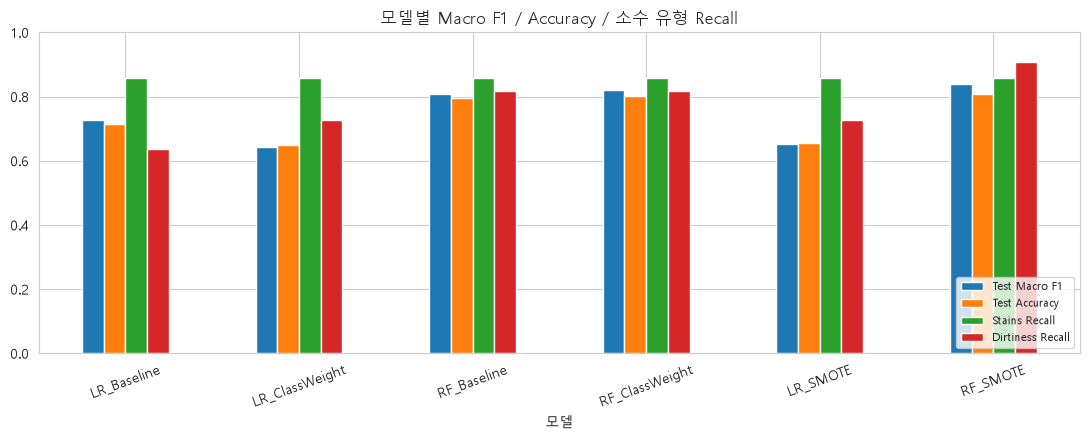

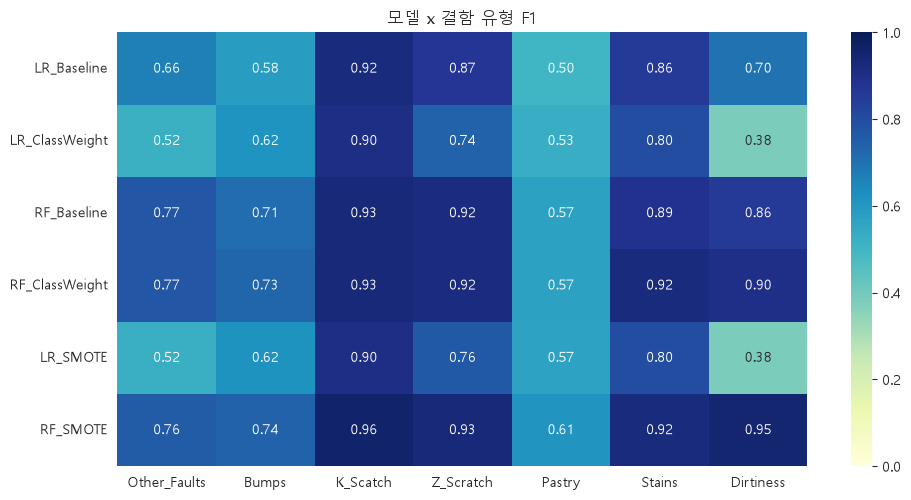

In [20]:
# 11-1. 모델별 주요 지표
show_cols = ["Test Macro F1", "Test Accuracy"] + [f"{m} Recall" for m in MINORITY]
summary[show_cols].plot(kind="bar", figsize=(11, 4.5))
plt.ylim(0, 1)
plt.title("모델별 Macro F1 / Accuracy / 소수 유형 Recall")
plt.xticks(rotation=20)
plt.legend(loc="lower right", fontsize=8)
savefig("model_compare_bar.png")

# 11-2. 모델 x 유형 F1
f1_mat = pd.DataFrame({n: pc["F1"] for n, pc in per_class.items()}).T
plt.figure(figsize=(10, 0.6 * len(f1_mat) + 1.5))
sns.heatmap(f1_mat, annot=True, fmt=".2f", cmap="YlGnBu", vmin=0, vmax=1)
plt.title("모델 x 결함 유형 F1")
savefig("model_per_class_f1.png")

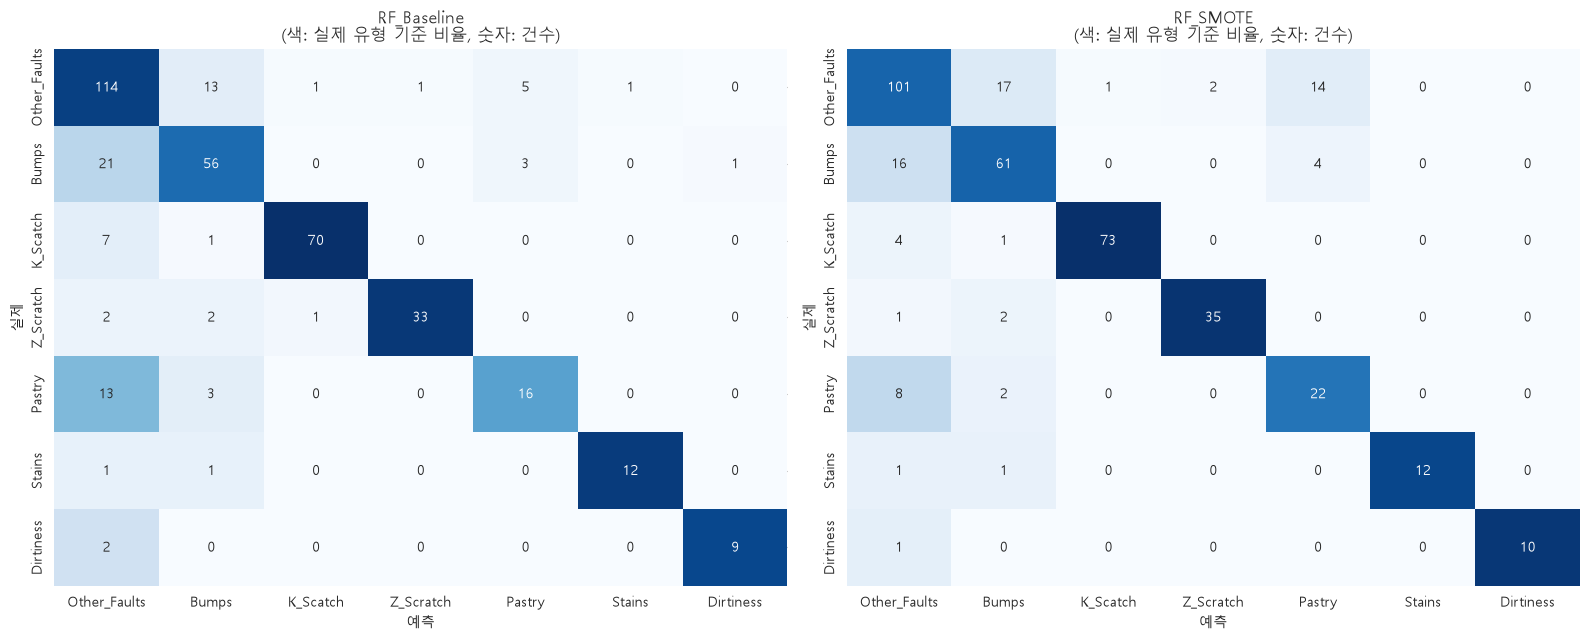

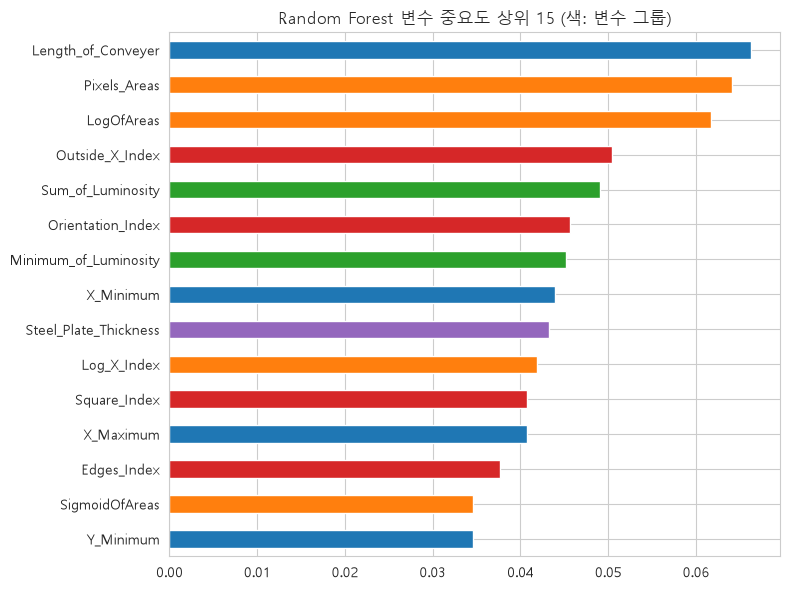

,Q3 ε² 순위,RF 중요도 순위
Length_of_Conveyer,19,1
Pixels_Areas,5,2
LogOfAreas,4,3
Outside_X_Index,2,4
Sum_of_Luminosity,1,5
Orientation_Index,15,6
Minimum_of_Luminosity,16,7
X_Minimum,14,8
Steel_Plate_Thickness,13,9
Log_X_Index,3,10


In [21]:
# 11-3. 혼동행렬: Baseline vs 최고 모델 (어떤 유형끼리 헷갈리는가)
compare = ["RF_Baseline", best] if best != "RF_Baseline" else ["RF_Baseline", "LR_Baseline"]
fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))
for ax, name in zip(axes, compare):
    cm = confusion_matrix(y_test, fitted[name][2], labels=labels_order)
    cm_norm = cm / cm.sum(axis=1, keepdims=True)
    sns.heatmap(cm_norm, annot=cm, fmt="d", cmap="Blues", cbar=False,
                xticklabels=labels_order, yticklabels=labels_order, ax=ax)
    ax.set_title(f"{name}\n(색: 실제 유형 기준 비율, 숫자: 건수)")
    ax.set_xlabel("예측")
    ax.set_ylabel("실제")
savefig("confusion_matrices.png")

# 11-4. RF 변수 중요도 (Q3 구분력 순위와 교차 확인)
rf_pipe, rf_feats, _ = fitted["RF_ClassWeight"]
imp = pd.Series(rf_pipe.named_steps["m"].feature_importances_, index=rf_feats).sort_values()
groups = list(FEATURE_GROUPS) + ["기타"]
colors = [sns.color_palette()[groups.index(GROUP_OF[f])] for f in imp.tail(15).index]
plt.figure(figsize=(8, 6))
imp.tail(15).plot(kind="barh", color=colors)
plt.title("Random Forest 변수 중요도 상위 15 (색: 변수 그룹)")
savefig("rf_feature_importance.png")

rank_cmp = pd.DataFrame({"Q3 ε² 순위": disc.set_index("변수")["효과크기(ε²)"].rank(ascending=False),
                         "RF 중요도 순위": imp.rank(ascending=False)}).sort_values("RF 중요도 순위")
display(rank_cmp.head(15).astype(int))

## 결과 해석 체크리스트

1. **Q1**: 정답 열 무결성에 문제가 없었는가? 제외된 행이 있었다면 몇 건인가?
2. **Q2**: 불균형 비율은 몇 배이며, 테스트셋의 Stains·Dirtiness는 몇 건인가? (1건당 Recall 변동 폭 함께 기재)
3. **Q3**: 구분력 상위 변수는 어느 그룹(크기·밝기·형상·위치·제품)에 속하는가? RF 중요도 순위와 일치하는가?
4. **Q4**: 이상치는 대부분 '유형 특징'이었는가, '오류 후보'였는가?
5. **Q5**: 중복 변수 쌍은 몇 개이며, 어떤 변수를 선형 모델에서 제외했는가?
6. **모델링**: 불균형 처리로 소수 유형 Recall·F1은 얼마나 올랐고, Accuracy 하락과 오경보 증가는 어느 정도였는가?